# 3. Customers, segments and retention
Do customers come back?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
import json
s = json.loads((OUT / "summary.json").read_text())
print(f"Customers who bought more than once: {s['repeat_customer_rate']:.1%}")
print(f"Share of revenue from repeat buyers: {s['repeat_revenue_share']:.1%}")

Customers who bought more than once: 3.0%
Share of revenue from repeat buyers: 5.6%


**Only about 3% of customers ever buy a second time.** This is the single biggest feature of the business: it is almost entirely a one-time-purchase marketplace, so growth depends on constantly finding new customers.

## Customer segments
Because nearly everyone has one order, classic RFM scoring is not useful. Segments are based on order count, recency (days since last purchase at the end of the data) and spend instead:

- **Repeat buyer** (2+ orders), active if the last order was within 180 days
- **One-timers** split by recency: recent (0 to 180 days), cooling (181 to 365), lost (over 365)
- **High-value recent one-timer**: recent and in the top quarter of one-time spenders

In [3]:
seg = pd.read_csv(OUT / "customer_segments.csv")
seg

,segment,customers,revenue,avg_revenue,customer_share,revenue_share
0,Cooling one-timer,34057,"4,627,969.96",135.89,0.36,0.34
1,High-value recent one-timer,9678,"3,320,799.26",343.13,0.10,0.25
2,Lost one-timer,20706,"2,857,672.43",138.01,0.22,0.21
3,Recent one-timer,27391,"1,895,935.32",69.22,0.29,0.14
4,Repeat buyer (lapsed),1629,"411,832.09",252.81,0.02,0.03
5,Repeat buyer (active),1246,"335,320.62",269.12,0.01,0.02


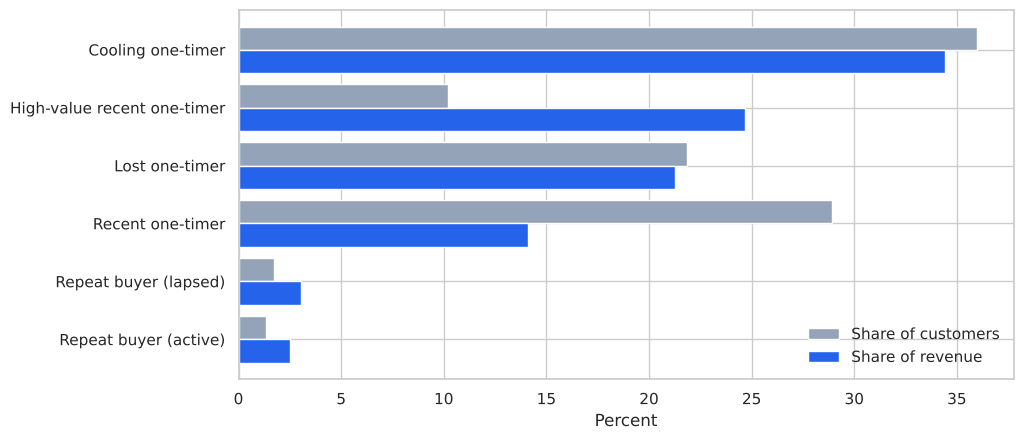

In [4]:
seg2 = seg.sort_values("revenue_share")
y = range(len(seg2))
plt.figure(figsize=(10, 4.8))
plt.barh([i + 0.2 for i in y], seg2["customer_share"] * 100, height=0.4, color="#94a3b8", label="Share of customers")
plt.barh([i - 0.2 for i in y], seg2["revenue_share"] * 100, height=0.4, color="#2563eb", label="Share of revenue")
plt.yticks(list(y), seg2["segment"]); plt.legend(frameon=False); plt.xlabel("Percent");

The **high-value recent one-timers** are about 10% of customers but 25% of revenue, with an average spend of BRL 343 versus about BRL 69 for other recent buyers. They are the best target for a second-purchase campaign.

## Cohort repeat-purchase rate
For each month of first purchase, what share of that cohort buys again in each later month?

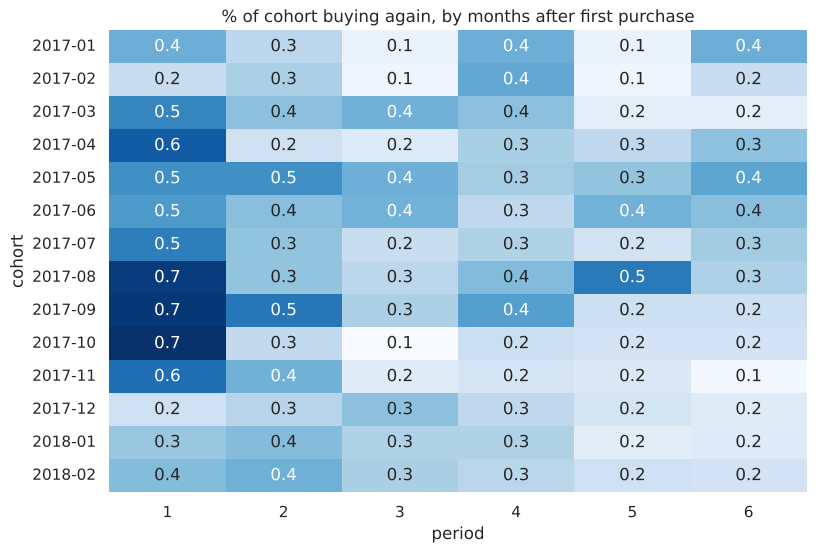

In [5]:
c = pd.read_csv(OUT / "cohort_retention.csv")
c = c[(c["period"].between(1, 6)) & (c["cohort"] >= "2017-01") & (c["cohort"] <= "2018-02")]
matrix = c.pivot(index="cohort", columns="period", values="retention") * 100
plt.figure(figsize=(9, 6)); sns.heatmap(matrix, annot=True, fmt=".1f", cmap="Blues", cbar=False)
plt.title("% of cohort buying again, by months after first purchase");

In [6]:
print(f"Average share of a cohort that buys again in month 3: {s['month3_retention']:.2%}")

Average share of a cohort that buys again in month 3: 0.25%


In any single month after the first purchase, only 0.1% to 0.7% of a cohort returns. There is no sign of a loyal group building up over time.